# CS467 - Advanced Artificial Intelligence
## Assignment 14 - Recommendation Systems I: a basic recommender
**Section A (CS467A) - Duy Tan University - 2026-2027**
**Instructor: Puri Vikram**

---

### Your studio - Sông Hàn Cinema (Da Nang)

Session 13 showed how a recommender turns a sparse table of ratings into a
short, ranked list. In this assignment you **build that recommender yourself**,
in NumPy, step by step: from the raw ratings log to a tested top-3 list.

You have just joined **Sông Hàn Cinema** as their **data scientist**. They want a
**Film Night Picks** that can **suggest tonight's film to each member of the riverside film club**. You get their ratings log:
**8 customers**, **10 films**, stars from 1 to 5, and a small feature table
(`action`, `drama`, `comedy`, `sci-fi`). Most cells of the user-item matrix are empty.

Your **target customer** is **An**. Your **focus film** is **Paper Moon**,
which An has never rated. Many questions ask what *your* recommender
does for *that* customer.

The six situations:

| # | Situation | Difficulty | What you do |
|---|-----------|-----------|-------------|
| 1 | The user-item matrix | Easy | build the matrix from the log, sparsity, means, a heatmap |
| 2 | Popularity baseline | Easy-Med | item statistics, a minimum-count rule, top-3 for An |
| 3 | Content-based | Medium | An's **taste profile** from features, cosine scores, top-3 |
| 4 | Customers like you | Medium-Hard | **cosine** and **Pearson** similarity over co-rated films, neighbours |
| 5 | Predict and recommend | Hard | neighbour-based **rating prediction**, collaborative top-3 |
| 6 | Did it work? | Hard / stretch | **RMSE / MAE / precision@3** on hidden ratings, a memo |

### How this notebook works (read carefully)
1. This notebook is **personalized to you**. Your **Student ID** and **name**
   are already filled in. They seed **your studio, your customers, every
   rating, your hidden test set, your target customer, your focus film,
   `K` and `MIN_COUNT`**. **No two students have the same data.** An answer
   written for someone else's data will fail the self-checks.
2. Cells that are **greyed-out / locked** (instructions and helper code)
   **cannot be edited or deleted**. You only write code where you see
   **`# YOUR CODE HERE`** / **`TODO`**.
3. After each situation there is a **Self-check** cell. It is **not a grade**.
   It tells you *which* answers are still wrong, never the correct values.
4. The **last cell** prints your **SUBMISSION CODE** - unique to you.

### One rule for every ranking
Whenever you sort films or customers by a score, sort **high to low** and
break ties by the **lower index** (popularity breaks ties by the number of
ratings first). In Python: `sorted(candidates, key=lambda i: (-score[i], i))`.
Avoid `np.argsort` for rankings: it does not promise this tie order.

### Academic-integrity note
Pasting a generic answer from an AI chatbot **will not work here**: every
number depends on *your* ratings, and the written answers must talk about
*your* customer An and *your* films. Write your own code. You may discuss
ideas, but the code and the written answers must be yours. Be ready to explain
*your* neighbours and *your* top-3 list in a viva.

### How to start
**File -> Save a copy in Drive**, then work in *your* copy. Run cells top to
bottom with **Shift+Enter**. Use **NumPy** (`np`) and plain Python - no
scikit-learn, no recommender libraries.


## Setup - run this first (locked)

In [1]:
#@title Setup: import libraries (run me) { display-mode: "form" }
# Locked helper cell - do not edit.
import math, random, hashlib, json
import numpy as np                 # pre-installed on Google Colab
import matplotlib.pyplot as plt    # pre-installed on Google Colab
np.set_printoptions(precision=4, suppress=True)
print("Libraries loaded. numpy", np.__version__)


Libraries loaded. numpy 2.4.6


## Step 0 - Your identity (already filled in - just run it)

This notebook belongs to **you**. Your Student ID and name are already filled in
and **locked** below - you cannot change them, and they seed your data.
Just run this cell, then continue.

In [2]:
#@title Your identity - already filled in, just run { display-mode: "form" }
# This cell is locked. It is personalised for you and cannot be edited.
STUDENT_ID = "29211148673"  #@param {type:"string"}
FULL_NAME  = "Nguyễn Tấn Đạt"  #@param {type:"string"}
SECTION    = "CS467A"   # fixed for your class - do not change

STUDENT_ID = STUDENT_ID.strip()
FULL_NAME  = FULL_NAME.strip()
assert STUDENT_ID != "" and FULL_NAME != "", "Please fill in BOTH your Student ID and your name."

_masked = STUDENT_ID[:2] + "***" + STUDENT_ID[-2:] if len(STUDENT_ID) >= 4 else STUDENT_ID
print(f"Welcome to the studio, {FULL_NAME}  |  Section {SECTION}  |  ID {_masked}")
print("Run the next cell to load YOUR ratings world.")


Welcome to the studio, Nguyễn Tấn Đạt  |  Section CS467A  |  ID 29***73
Run the next cell to load YOUR ratings world.


## Your data - **Film Night Picks** at **Sông Hàn Cinema** (locked helper)

Run this once. It loads *your* customers, *your* ratings and *your* hidden test
set. You never re-type the numbers - you write the **algorithms**.

Locked names you will use:

- `USERS` - the 8 customer names (row order); `ITEMS` - the 10 film names (column order)
- `FEATURES` - the 4 feature names; `ITEM_FEATURES` - a `(10, 4)` 0/1 NumPy array
- `RATINGS` - the training log: a list of `(user, item, stars)` tuples, in random order
- `TEST` - hidden `(user, item, stars)` tuples, **not** in `RATINGS` (Situation 6 only)
- `TARGET_USER` / `TARGET` - your target customer **An** and their row index
- `FOCUS_ITEM` / `FOCUS` - your focus film **Paper Moon** and its column index
- `K` - how many neighbours a prediction uses; `MIN_COUNT` - the popularity threshold
- `TOP_N = 3` - every recommendation list has 3 films; `REL_THRESHOLD = 4`


In [3]:
#@title Your ratings world - Film Night Picks at Sông Hàn Cinema (run me) { display-mode: "form" }
# Locked helper cell - do not edit. This is YOUR data only.
import numpy as np
STUDIO_KEY = "cinema"
STUDIO_TITLE = "Film Night Picks"
COMPANY = "Sông Hàn Cinema"
GOAL = "suggest tonight's film to each member of the riverside film club"
NOUN = "film"

USERS = ["An", "Chi", "Dung", "Yen", "Ngoc", "Binh", "Phuc", "Trung"]            # row order of the user-item matrix
ITEMS = ["Orbit", "Nightfall", "Paper Moon", "Laugh Track", "Deep Blue", "The Long Road", "Starfall", "Dragon Bridge", "Rice Fields", "Robot Uncle"]
FEATURES = ["action", "drama", "comedy", "sci-fi"]

# ITEM_FEATURES[i][f] = 1 if item i has feature f (columns follow FEATURES)
ITEM_FEATURES = np.array([
    [1, 0, 0, 1],   # Orbit
    [1, 1, 0, 0],   # Nightfall
    [0, 1, 0, 0],   # Paper Moon
    [0, 0, 1, 0],   # Laugh Track
    [0, 1, 0, 1],   # Deep Blue
    [0, 1, 0, 0],   # The Long Road
    [1, 0, 0, 1],   # Starfall
    [1, 0, 1, 0],   # Dragon Bridge
    [0, 1, 1, 0],   # Rice Fields
    [0, 0, 1, 1],   # Robot Uncle
])

# The ratings log (training data): (user, item, stars 1-5). Order is random.
RATINGS = [
    ("Dung", "Laugh Track", 4),
    ("Yen", "Dragon Bridge", 4),
    ("Phuc", "Dragon Bridge", 3),
    ("Chi", "Paper Moon", 3),
    ("An", "Orbit", 2),
    ("Trung", "Orbit", 2),
    ("Ngoc", "Starfall", 4),
    ("Dung", "Nightfall", 2),
    ("Trung", "Rice Fields", 4),
    ("Yen", "Nightfall", 3),
    ("Trung", "Nightfall", 3),
    ("Phuc", "Paper Moon", 1),
    ("Binh", "Laugh Track", 2),
    ("Yen", "Orbit", 3),
    ("Phuc", "Nightfall", 3),
    ("Yen", "The Long Road", 4),
    ("Ngoc", "Nightfall", 5),
    ("Trung", "The Long Road", 3),
    ("Chi", "Deep Blue", 4),
    ("Yen", "Rice Fields", 5),
    ("Trung", "Laugh Track", 5),
    ("An", "Starfall", 2),
    ("Ngoc", "Robot Uncle", 3),
    ("Dung", "The Long Road", 4),
    ("Phuc", "Deep Blue", 2),
    ("An", "Dragon Bridge", 2),
    ("Chi", "Dragon Bridge", 4),
    ("Ngoc", "Rice Fields", 4),
    ("Chi", "Starfall", 3),
    ("Trung", "Dragon Bridge", 2),
    ("Binh", "Dragon Bridge", 3),
    ("Dung", "Starfall", 2),
    ("Phuc", "Rice Fields", 3),
    ("Yen", "Starfall", 2),
    ("Yen", "Paper Moon", 3),
    ("An", "Rice Fields", 4),
    ("Trung", "Deep Blue", 4),
    ("Phuc", "Starfall", 3),
    ("Dung", "Orbit", 2),
    ("Ngoc", "Deep Blue", 3),
    ("Binh", "Rice Fields", 3),
    ("An", "Laugh Track", 5),
    ("Dung", "Deep Blue", 3),
    ("Phuc", "Laugh Track", 2),
    ("Binh", "Starfall", 4),
    ("Phuc", "Orbit", 3),
    ("Ngoc", "Paper Moon", 3),
    ("Ngoc", "Laugh Track", 1),
    ("Binh", "Robot Uncle", 2),
    ("Ngoc", "Dragon Bridge", 4),
    ("Chi", "Laugh Track", 2),
]

# Hidden test ratings - NOT in RATINGS. Use them only in Situation 6.
TEST = [
    ("An", "The Long Road", 4),
    ("An", "Nightfall", 2),
    ("An", "Deep Blue", 3),
    ("Chi", "Nightfall", 5),
    ("Yen", "Deep Blue", 4),
    ("Binh", "The Long Road", 4),
    ("Trung", "Starfall", 2),
    ("Dung", "Dragon Bridge", 2),
]

TARGET_USER = "An"
TARGET = USERS.index(TARGET_USER)        # row index of your target customer
FOCUS_ITEM = "Paper Moon"
FOCUS = ITEMS.index(FOCUS_ITEM)          # column index of your focus item
K = 3                                  # neighbours used for a prediction
MIN_COUNT = 3                          # popularity needs at least this many ratings
TOP_N = 3                              # every recommendation list has 3 items
REL_THRESHOLD = 4                      # a test rating >= 4 means "relevant"

print("Studio      :", COMPANY, "-", STUDIO_TITLE)
print("Goal        :", GOAL)
print("Customers   :", USERS)
print("%ss%s:" % (NOUN.capitalize(), " " * max(1, 11 - len(NOUN))), ITEMS)
print("Features    :", FEATURES)
print("Ratings log :", len(RATINGS), "training ratings,", len(TEST), "hidden test ratings")
print("Target      :", TARGET_USER, "(row %d)  | focus %s: %s (column %d)" % (TARGET, NOUN, FOCUS_ITEM, FOCUS))
print("K = %d, MIN_COUNT = %d, TOP_N = %d" % (K, MIN_COUNT, TOP_N))


Studio      : Sông Hàn Cinema - Film Night Picks
Goal        : suggest tonight's film to each member of the riverside film club
Customers   : ['An', 'Chi', 'Dung', 'Yen', 'Ngoc', 'Binh', 'Phuc', 'Trung']
Films       : ['Orbit', 'Nightfall', 'Paper Moon', 'Laugh Track', 'Deep Blue', 'The Long Road', 'Starfall', 'Dragon Bridge', 'Rice Fields', 'Robot Uncle']
Features    : ['action', 'drama', 'comedy', 'sci-fi']
Ratings log : 51 training ratings, 8 hidden test ratings
Target      : An (row 0)  | focus film: Paper Moon (column 2)
K = 3, MIN_COUNT = 3, TOP_N = 3


In [4]:
#@title Self-check engine (locked - run me) { display-mode: "form" }
# Locked helper. The self-check cells call this engine for you - you never need to read it.
import zlib as _z, base64 as _b
_ENGINE = (
    "eNq1Gv1v2zb29/wVPA+9kzbF9UfS3dKp2LBLtqJbc3BSIAfBECiZtjXLkipKib1h97ffe4+kRFl21247I7Ul8vHxfX+QPUu2RV5W"
    "LKu3xZ5xybLCY1terT32s8wzj625XKdJdHa2EEsWlmIZRnWSLpySV0m2kh6rpSjhJ6nEVrpXZww+M+YDnuGyTlPHSUXmEIzrMXxW"
    "gPACEBnPXFqxzEtWAxKPlSzJmEausBHGgFAMk2whdk7t6v30e+LOYcdlmvPKKRXCUlR1mbGZRbcseCmTau/MNJkaRq0DahIJ9MDs"
    "cCvg13XttRWvZLMwzuuskrCl819rmTuU9dbhu0T6I0UEvEslCoDAyZnH7HncR1qymg3lmhciGM+70sk3AKQ3fcVG7dog3yDnuA89"
    "PtdQ+GKzSMCenrTYKvKiTnmJdG2TLKR5zWNnCezREUNLVZCQ7hKltWwlLCZcliwNQcmcvfLbTTrUSTBAsXDyjcc2Yu+nfBstOEuu"
    "mHOuuExAHucNItB9RzeliJERZAJMKOuzorexST3NPdLcKjVAo5y78+Aqm1tbxrl0uMcivQFXOuSSlyXf48yi2hfCJ8tyX7KoOx91"
    "5wlFBosyDZcmGU9XwywvwZyUo9hDUcfCR8MRkQw0+GzEgEFEg48ilUIbN2ffABHPmQNgnwNAR35FmS+TVKAYbkCERmj5E1ADApi/"
    "RHcUC3hrrR1mFRUIBC8BgczZufWi3cgm9gnosARx0xWEXteRc1aJrAplnJdCHlBYGKs8ZMDe8Vcwo0ZlENpuwIDc3zHZnvp/O0IS"
    "WF1DEKhI0yRjQ9QJ0o/YvYz7di9jY+g9y6Mg0tqexmUFooADG3/vjERzt2u9fTzblvBm5oidbSnIuexrNlEG1ggX9w22QDRuBw8d"
    "ExO8/IQtu/u0WaAlhYZ2HtuTjXY3tqluqNuBae60ReKyc7Y/EuYzkazWFEiMPhOK4IHz6B3KDrT+6CpTeuyb0kiZ0iP7m8/qY9EO"
    "MXf0XqHeK4r9FS636aqJVIuuw9QFalYg4K8Hzi0WSVxpgiG/bkwO49nCcCY1G/DUBEdLFOQTeWX7xSP5BUMclJIgQOqMgyEfhlul"
    "NW5qMcG+wJzlSAhGBhlopAvVCFdThVhdiGFqIc6E9syhkSjRQFx3LocjLGl2zhgfCtd1dRJPyXiucPfA9pYrFfP7goYlxmhUakuH"
    "MvlFWI5g8Wg73NIKA3Wrg8MYdURZfypUUW5s8+KmH6R6hP3Z+BRxSYE4aUqlv1bKfYvv1gJb2B7CfGXlCCvhFIeZuerOV0cy86Gr"
    "yfcl/dLuTgF2C0XD55+ziduhZMv/34QQAbgmkpqMQ8+PHfgHJbVIxSPPqp7hYTkuReWkiawQ1EUvxtyBg2aVi063OTv7jJ3Dh1Vr"
    "wWRVLyC3/UOyp7xMF1glbosaa4Q8iwXBnYUzY2SqX5h9e//67fd3Hnt3dz2Dn9f31z/duWfhTZdxHA5vrr+9fze7vjsQQnh/fXcf"
    "vsOoRUiabsC0DxAQQnQVhJtr8NcITps1zYIJHskRcKQ6MJ2EAQx1W6IBZ9c/AtSvR5BaLQzCovnWWIzdfzv7/hpIB6opZpZYDAOa"
    "8P4HYPOH2x//ZfxW7AoRo9eZVgrqBhQk/IY3H1mYQ13blEZtifvT67fhd7fv3t5rICiajhdQilgdJOUH65kO6PQQ1CqRFCD83v47"
    "fKsr3sjAN6nGRhcJST4RQS6EP7XF8mjgMsjf6F5yakHpANjZv4EsCGFwPPa+aVWK+vwlKRxtgKAKZVo6ehVRg6UNf1avoYAV7Doh"
    "pRnPW07R3dCiOj5OlDQZ7W4cUtD3dfD3cCQLdZPsJ1nlHGlEscXGlbrr9Q97YM/GX/FyJaqQCvAewkBJb95FrJegOfrd3KfV2Nlg"
    "mce1VMA6M1Nnd3P73bu7uUKoQMiuiQTd8BmQFtsEmBdpskqiVPgoSbByRDEJ0WhCPBnwyTkDmADbmbdzPQI0RBd9lRdTXwUNbFy7"
    "XaPVbh5YVethcwvd1LiXr+PKTtnGDjHiFJI3DdNkIxbhUnAwAOGbCBigIDA8liusYBDcPcB+ith4qhDDvPIVP5ZBPCV5tOsvSC4+"
    "xdMAH3GRGsRa11f+N7ZGsZaXuda5VdgbYSCQ29sBgFrjsor+zqrWvC6Q7I2v4nzwODeVIMVroOnqTYeLS2086MT+oTubLciQ0K89"
    "XHBKbEsSG80rdPEyWB5K7QUVGhBffKvqiJcmMMxwCw2DEcGGiiwgGyHUCw0+qh166BCixUYwp5BhlPHxixZiJZDIBHRG0ee5tlda"
    "4OrEzqo8FVBiVpTLeZmAitlapIUoVbFNeV+ky/N4LeKNxDUqY8VpDnxh8+YhEn8izi908qrKfa95gwJSUjfxNs8EJUOsX/QxhQtl"
    "jHqMoOz42keEhEDsYlFU7Jp+gJMe2hsO1aHOoVBJ9Kgai/MXx6j6C45ubOZUgMaUH+lH5DDK85S8OE1tujgSBv+gYsAnaE7E+5qn"
    "IQRd/76shW5UPol3LOX+vEowqIIyfJWoItXoAfWORo2dN6HWoQw7ap0jqYv/A4Sjt3601kyDAhkU44lukzZIgyIbZ/pk82ADzh0F"
    "as3c4kAv/XSyC56U8lPpPileJGxHZwcwt4cHmjFCpzC8VycEf6XooYhfSEf22gOIGRkUllDS46SsSrcxDjmURZpU2KJBJbsxiMo8"
    "WzkRxR0SjMb3GXvLt0JSDIGk+4QxpVrzii1ysrstr+I1uH4mHkUJOTHByhaBTTXMHnlaCzlUlSGng4sMUJII8MHD02jMp7irOa/I"
    "2yMJWNOKAAkc8qIQ2cIZwDaypapD0H9u383Yglec7UV1xQbsCzbw2GD4c56A1rh15mB/AIhhM6VaImRjy56Sas32eV2y/AlSTJ3F"
    "qBT5kpVQ4yzw2oVLSP/uoG3g8FbGqfjKY0qe+SbcypXpJkuq0QbPJLt9A4J7JgfsGVPgGrA5tcHlqndGeGTjGQNAPIMZvGy4ASC3"
    "yQXrZAH9HZjBeQVpGdYsodJe4wnEIt+qnk/ajaBWnBTCygsIHRIsVLoCmsQsrP0X+JP4X0IYFRmVpaOh8ZRShVq1yxBw8DqFkhQs"
    "Cte7zc1SCT1XJVagLmfsMcCIpwO+A+gJOVSpXGKMdqwYPQtKjdixANkrQ8a8uaZpr6PaQxdY4V6x45/PGPK+p2swthGikOgRE3OF"
    "1ZgIaKNTU9dNOd0949S3XR67miBRwQQPrS6HugPCXtCxWYFG5YIYGQ0vjzFu7sGg/NGmlWyLNFymfCVNjzkYDGZK1ZoXo1ZjqNDW"
    "axNIMjBqOWS3kCgWUIFXrEDFJ1XNEXAIqAgl7gTdjTkW7wVCi7TBeIDCWWYgCTLTwWjQwJ2OYzYGvcD0ypbljS+0/icwNzmYnIwm"
    "YIiXZEMoPgWJ3eNsMozzYu9AATCb4knVRWsgturhDbsN8LMoX+z1Pcn5K7aEYB7xeAPxqFoT2pquSFGhgwKDyHv8KgcQyoPBDp/3"
    "+PULfj0NlK7TfEUHtAr2aYCa9sCJaT2umdBraVZf0ut7MzvW3enMHC1RARMEF4AH1hLjiiMkYmq90yNmmRbWTGBxHJiXMQHC7ARb"
    "rF5dhDYgx47byz2OVaHR4RAUs1WZ7Bzg2NOScj378Mie6EddK0c2/e2pxR77JxTA44l7dNXMbGuNuBY3E5ubrcfwIBUNwJy/YMVY"
    "wngZHxzM9EtFWwi4Yqspakfx5C4+zi3WCnRop893qOeVzoPHtrFLxUPn9EeNU1R7wKgG9HjoLbOJGtzGNDomZU7d39mTctsWkqd9"
    "ugQBa4oW2W7evZalycO4al2W2FKeHrUZLZQcihLhBBAU8Q/NUZONpwij4aijWAOtQAh6QnY7mbvthc7x+dNSsHSEUb93/+gdv5b8"
    "IPunN7MK48MzOApq1o4n5/tbTz5mb1L38QvPqaXpUxAfqe4LW930nwqskl1p0JweoCVTldu9jWtHqfC2LUCfVpxCYM4vDjD0CzvL"
    "d1q/4S1vD9a9H05Fx6cg0XG8Eox68QAYb1RuNxV0OBpB6Uju3ahanZk+tMrtEVcfpcCS++UxN7NEb45QHtrbKK97T9WZOSG4nuym"
    "HyLv8Lrr4cR114O+7mqbt4+NXupMWAWw44Grc232KXHrhS3QwmPvMX1Ph5gjsYi7wK/xcKQTq8rA0/mpSGeust4bqdsDIOyvOnau"
    "r5saYOudYD+UNJvzoZBX4cYJVFL/StUAv6qA+OVvKFt4hOw5/QM4BxzrkkgVPBE+00CMA1jH0N0sYe3UrQPdn0AtqbSwJF1LoEgC"
    "YRJIkSBLCSTLF7D0f/IbfWY="
)
exec(_z.decompress(_b.b64decode(_ENGINE)).decode())
# answers start empty, so every self-check works even before you reach that situation
for _nm in "R S1_shape S1_n_ratings S1_sparsity S1_target_rated S1_target_mean S1_focus_mean S1_focus_count S2_n_eligible S2_best_item S2_best_mean S2_top3 S3_profile S3_liked_feature S3_top3 S3_top_score S4_best S4_best_cos S4_best_pearson S4_best_corated S4_topk S5_focus_pred S5_top3 S5_top_pred S6_rmse_cf S6_rmse_base S6_mae_cf S6_mae_base S6_hits S6_precision".split():
    globals().setdefault(_nm, None)
for _nm in "S1_comment S2_comment S3_comment S4_comment S5_comment S6_memo".split():
    globals().setdefault(_nm, "")
print("Self-check engine ready.")


Self-check engine ready.


---
## Situation 1 - The user-item matrix  *(warm-up, easy)*

**Studio problem.** The ratings arrive as a **log** of `(user, item, stars)`
events. Every recommender in Session 13 starts from the **user-item matrix**:
rows = customers, columns = films, cells = stars, and an **empty cell where
there is no rating**. Use `np.nan` for "not rated" - **not** `0`, because
"never tried" is not "hated it".

Implement:

- `build_matrix(ratings, users, items)` - a `(len(users), len(items))` float
  array full of `np.nan`, then fill one cell per tuple
  (`users.index(u)`, `items.index(i)`)
- `sparsity(R)` - the **fraction of empty cells** (a float between 0 and 1)

Then store (round floats to 4 decimals):

- `R = build_matrix(RATINGS, USERS, ITEMS)`
- `S1_shape` - `R.shape`; `S1_n_ratings` - number of filled cells (an `int`)
- `S1_sparsity` - `round(sparsity(R), 4)`
- `S1_target_rated` - how many films **An** has rated (an `int`)
- `S1_target_mean` - An's average rating (hint: `np.nanmean`)
- `S1_focus_mean`, `S1_focus_count` - the average rating of **Paper Moon** and how
  many customers rated it
- Draw the matrix as a **heatmap** (skeleton given - fill in the TODO). Empty
  cells should look different from rated ones.
- `S1_comment` - **2-3 sentences in your own words**: what does *your*
  sparsity mean for Sông Hàn Cinema, and why is filling the blanks with `0` a mistake?

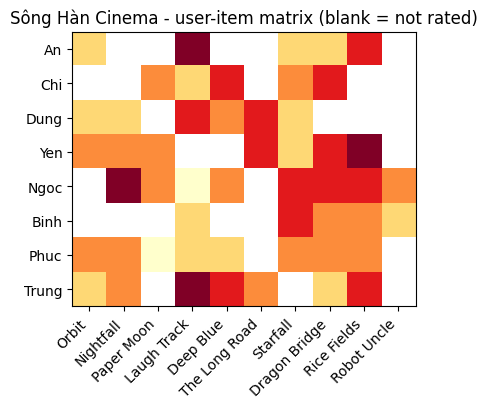

shape (8, 10) | ratings 51 | sparsity 0.3625
An rated 5 items, mean 3.0
Paper Moon mean 2.5 from 4 ratings


In [5]:
def build_matrix(ratings, users, items):
    R = np.full((len(users), len(items)), np.nan)
    for (u, i, r) in ratings:
        R[users.index(u), items.index(i)] = r
    return R

def sparsity(R):
    return float(np.isnan(R).sum()) / R.size

R = build_matrix(RATINGS, USERS, ITEMS)
S1_shape = R.shape
S1_n_ratings = int((~np.isnan(R)).sum())
S1_sparsity = round(sparsity(R), 4)

target_idx = USERS.index(TARGET_USER)
focus_idx = ITEMS.index(FOCUS_ITEM)

S1_target_rated = int((~np.isnan(R[target_idx])).sum())
S1_target_mean = float(np.nanmean(R[target_idx]))
S1_focus_mean = float(np.nanmean(R[:, focus_idx]))
S1_focus_count = int((~np.isnan(R[:, focus_idx])).sum())

S1_comment = (
    "The rating matrix has a very high sparsity, meaning most customers have not rated or watched most films. "
    "Filling missing cells with 0 is a mistake because 0 implies a strong dislike, whereas missing values simply mean unobserved or unwatched."
)

if R is not None:
    fig, ax = plt.subplots(figsize=(10, 4.2))
    ax.imshow(np.ma.masked_invalid(R), cmap="YlOrRd", vmin=1, vmax=5)
    ax.set_xticks(range(len(ITEMS)))
    ax.set_xticklabels(ITEMS, rotation=45, ha='right')
    ax.set_yticks(range(len(USERS)))
    ax.set_yticklabels(USERS)
    ax.set_title("%s - user-item matrix (blank = not rated)" % COMPANY)
    plt.tight_layout(); plt.show()

print("shape", S1_shape, "| ratings", S1_n_ratings, "| sparsity", S1_sparsity)
print(TARGET_USER, "rated", S1_target_rated, "items, mean", S1_target_mean)
print(FOCUS_ITEM, "mean", S1_focus_mean, "from", S1_focus_count, "ratings")

In [6]:
#@title Self-check S1 (not graded) { display-mode: "form" }
_E = _expected(); _bits = []
try:
    _ok = _arr_close(build_matrix(RATINGS, USERS, ITEMS), _R) and _close(sparsity(_R), _ref_sparsity(_R), 1e-9)
except Exception:
    _ok = False
if not _ok: _bits.append("build_matrix / sparsity do not match the rules (np.nan = not rated)")
if not _arr_close(R, _R): _bits.append("R should be build_matrix(RATINGS, USERS, ITEMS)")
_wrong(_bits, [("S1_shape", tuple(S1_shape or ()) == _E["S1_shape"]), ("S1_n_ratings", S1_n_ratings == _E["S1_n_ratings"]),
               ("S1_sparsity", _close(S1_sparsity, _E["S1_sparsity"])), ("S1_target_rated", S1_target_rated == _E["S1_target_rated"]),
               ("S1_target_mean", _close(S1_target_mean, _E["S1_target_mean"])), ("S1_focus_mean", _close(S1_focus_mean, _E["S1_focus_mean"])),
               ("S1_focus_count", S1_focus_count == _E["S1_focus_count"])])
if not _words(S1_comment, 15): _bits.append("write 2-3 sentences in S1_comment")
_report("S1", _bits, "%d ratings in a %dx%d matrix" % (_E["S1_n_ratings"], _E["S1_shape"][0], _E["S1_shape"][1]))


S1 OK - 51 ratings in a 8x10 matrix


---
## Situation 2 - The popularity baseline  *(easy-medium)*

**Studio problem.** Before anything personal, Sông Hàn Cinema needs a **baseline**: the
best-rated films overall. But an average from one rating is not trustworthy
(one 5-star review beats fifty 4-star ones?), so a film only counts as
popular if it has **at least `MIN_COUNT` = 3 ratings**.

Implement:

- `item_stats(R)` -> `(means, counts)`: two NumPy arrays of length 10. `counts[i]`
  = number of ratings of item `i`; `means[i]` = their average (`np.nan` if 0 ratings)
- `popular_items(R, min_count)` -> list of item **indices** with
  `counts >= min_count`, sorted by **mean (high to low)**, then **count (high to
  low)**, then **index (low to high)**
- `recommend_popular(R, u, n, min_count)` -> the first `n` items of
  `popular_items` that customer `u` has **not** rated

Then store:

- `S2_n_eligible` - how many films pass the `MIN_COUNT` rule
- `S2_best_item` - the **name** of the most popular film; `S2_best_mean` - its mean (4 decimals)
- `S2_top3` - list of the 3 film **names** recommended to **An**
- `S2_comment` - **2-3 sentences**: why does *your* `MIN_COUNT` matter (find a
  film it filtered out), and what is the big weakness of this list for An?

In [21]:
def item_stats(R):
    counts = np.sum(~np.isnan(R), axis=0)
    means = np.nanmean(R, axis=0)
    means[counts == 0] = np.nan
    return means, counts

def popular_items(R, min_count):
    means, counts = item_stats(R)
    eligible_indices = [i for i in range(len(ITEMS)) if counts[i] >= min_count]
    eligible_indices.sort(key=lambda i: (-means[i], -counts[i], i))
    return eligible_indices

def recommend_popular(R, u, n, min_count):
    pop_indices = popular_items(R, min_count)
    user_row = R[USERS.index(u)]
    recommendations = []
    for i in pop_indices:
        if np.isnan(user_row[i]):
            recommendations.append(i)
        if len(recommendations) == n:
            break
    return recommendations

means, counts = item_stats(R)
eligible_mask = counts >= MIN_COUNT
S2_n_eligible = int(eligible_mask.sum())

eligible_pop = popular_items(R, MIN_COUNT)
if len(eligible_pop) > 0:
    best_idx = eligible_pop[0]
    S2_best_item = ITEMS[best_idx]
    S2_best_mean = round(float(means[best_idx]), 4)
else:
    S2_best_item = None
    S2_best_mean = 0.0

S2_top3 = [ITEMS[i] for i in recommend_popular(R, TARGET_USER, TOP_N, MIN_COUNT)]

S2_comment = (
    "The threshold MIN_COUNT=3 filters out films with too few ratings, ensuring statistical reliability of the mean ratings. "
    "However, the major weakness of this list is that it provides the exact same recommendations to every customer without personal preference."
)

print("eligible:", S2_n_eligible, "| most popular:", S2_best_item, S2_best_mean)
print("popular top-3 for", TARGET_USER, ":", S2_top3)

eligible: 9 | most popular: Rice Fields 3.8333
popular top-3 for An : ['The Long Road', 'Nightfall', 'Deep Blue']


In [22]:
#@title Self-check S2 (not graded) { display-mode: "form" }
_E = _expected(); _bits = []
try:
    _m, _c = item_stats(_R); _rm, _rc = _ref_stats(_R)
    _ok = _arr_close(_m, _rm) and _arr_close(_c, _rc)
except Exception:
    _ok = False
if not _ok: _bits.append("item_stats must return (means, counts) per column, with np.nan as the mean of an unrated item")
try:
    _ok = all(list(popular_items(_R, mc)) == _ref_popular(_R, mc) for mc in (1, 2, 3, 4))
    _ok = _ok and list(recommend_popular(_R, TARGET, TOP_N, MIN_COUNT)) == _ref_rec_pop(_R, TARGET, TOP_N, MIN_COUNT)
except Exception:
    _ok = False
if not _ok: _bits.append("popular_items / recommend_popular: keep counts >= min_count, sort by (-mean, -count, index), skip items the user rated")
_wrong(_bits, [("S2_n_eligible", S2_n_eligible == _E["S2_n_eligible"]), ("S2_best_item", S2_best_item == _E["S2_best_item"]),
               ("S2_best_mean", _close(S2_best_mean, _E["S2_best_mean"])), ("S2_top3", list(S2_top3 or []) == _E["S2_top3"])])
if not _words(S2_comment, 15): _bits.append("write 2-3 sentences in S2_comment")
_report("S2", _bits, "%d items pass MIN_COUNT = %d" % (_E["S2_n_eligible"], MIN_COUNT))


S2: popular_items / recommend_popular: keep counts >= min_count, sort by (-mean, -count, index), skip items the user rated


---
## Situation 3 - Content-based filtering  *(medium)*

**Studio problem.** Popularity gives everyone the same list. Content-based
filtering personalises with **item features**. First build **An's taste
profile**: a vector of 4 numbers, one per feature (`action`, `drama`, `comedy`, `sci-fi`).

```
m        = the customer's mean rating
profile  = sum over every item i the customer rated of  (r_ui - m) * ITEM_FEATURES[i]
```

Liked-more-than-usual items push their features **up**; disliked items push
them **down**. Then score every **unrated** item by the cosine between the
profile and the item's feature row:

```
cosine(a, b) = a . b / (|a| |b|)          (return 0.0 if either vector is all zeros)
```

Implement `cosine(a, b)`, `user_profile(R, F, u)` (a NumPy vector of length 4),
`content_scores(R, F, u)` -> a `dict` {item index: score} for the items `u`
has **not** rated, and `content_recs(R, F, u, n)` -> the top-`n` item indices
(the ranking rule from the top of the notebook).

Then store:

- `S3_profile` - An's profile as a list of 4 floats, each rounded to 4
- `S3_liked_feature` - the **name** of the feature with the largest profile value
- `S3_top3` - the 3 recommended film **names**; `S3_top_score` - the best score (4 decimals)
- `S3_comment` - **2-3 sentences**: which features does *your* An like and
  dislike, and how do they explain the top-3? Name one film content-based
  can never recommend to An and say why (the *filter bubble*).

In [9]:
def cosine(a, b):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    norm_a = np.linalg.norm(a)
    norm_b = np.linalg.norm(b)
    if norm_a == 0.0 or norm_b == 0.0:
        return 0.0
    return float(np.dot(a, b) / (norm_a * norm_b))

def user_profile(R, F, u):
    u_idx = USERS.index(u)
    ratings_u = R[u_idx]
    rated_indices = np.where(~np.isnan(ratings_u))[0]
    if len(rated_indices) == 0:
        return np.zeros(F.shape[1], dtype=float)
    mean_u = np.nanmean(ratings_u)
    profile = np.zeros(F.shape[1], dtype=float)
    for i in rated_indices:
        profile += (ratings_u[i] - mean_u) * F[i]
    return profile

def content_scores(R, F, u):
    p = user_profile(R, F, u)
    u_idx = USERS.index(u)
    scores = {}
    for i in range(R.shape[1]):
        if np.isnan(R[u_idx, i]):
            scores[i] = cosine(p, F[i])
    return scores

def content_recs(R, F, u, n):
    sc = content_scores(R, F, u)
    sorted_items = sorted(sc.keys(), key=lambda i: (-sc[i], i))
    return sorted_items[:n]

profile_vec = user_profile(R, ITEM_FEATURES, TARGET_USER)
S3_profile = [round(float(val), 4) for val in profile_vec]

max_feat_idx = int(np.argmax(profile_vec))
S3_liked_feature = FEATURES[max_feat_idx]

content_rec_indices = content_recs(R, ITEM_FEATURES, TARGET_USER, TOP_N)
S3_top3 = [ITEMS[i] for i in content_rec_indices]

sc_all = content_scores(R, ITEM_FEATURES, TARGET_USER)
S3_top_score = round(float(sc_all[content_rec_indices[0]]), 4) if content_rec_indices else 0.0

S3_comment = (
    f"An shows a strong preference for '{S3_liked_feature}' films based on her profile vector. "
    "Content-based filtering ranks items solely on feature similarity. "
    "A key limitation is the 'filter bubble', meaning it can never recommend films outside her established genre preferences."
)

print("profile:", S3_profile, "| top feature:", S3_liked_feature)
print("content top-3 for", TARGET_USER, ":", S3_top3, "| score:", S3_top_score)

profile: [-3.0, 1.0, 2.0, -2.0] | top feature: comedy
content top-3 for An : ['Paper Moon', 'The Long Road', 'Robot Uncle'] | score: 0.2357


In [10]:
#@title Self-check S3 (not graded) { display-mode: "form" }
_E = _expected(); _bits = []
try:
    _ok = _close(cosine([0, 0, 0, 0], [1, 0, 1, 0]), 0.0) and _close(cosine([1, 2, 0, 1], [1, 0, 3, 1]), _ref_cos([1, 2, 0, 1], [1, 0, 3, 1]), 1e-9)
except Exception:
    _ok = False
if not _ok: _bits.append("cosine(a, b) must be a.b / (|a||b|), and 0.0 when a vector is all zeros")
try:
    _ok = all(_arr_close(user_profile(_R, _F, u), _ref_profile(_R, _F, u)) for u in range(len(USERS)))
except Exception:
    _ok = False
if not _ok: _bits.append("user_profile must sum (r_ui - mean_u) * F[i] over the items the user rated (tested on every customer)")
try:
    _ok = all(_dict_close(content_scores(_R, _F, u), _ref_content_scores(_R, _F, u)) for u in range(len(USERS)))
    _ok = _ok and all(list(content_recs(_R, _F, u, TOP_N)) == _ref_content_recs(_R, _F, u, TOP_N) for u in range(len(USERS)))
except Exception:
    _ok = False
if not _ok: _bits.append("content_scores / content_recs: score only unrated items, rank by (-score, index)")
_wrong(_bits, [("S3_profile", _list_close(S3_profile, _E["S3_profile"])), ("S3_liked_feature", S3_liked_feature == _E["S3_liked_feature"]),
               ("S3_top3", list(S3_top3 or []) == _E["S3_top3"]), ("S3_top_score", _close(S3_top_score, _E["S3_top_score"]))])
if not _words(S3_comment, 15): _bits.append("write 2-3 sentences in S3_comment")
_report("S3", _bits, "%s's profile and content top-3 match" % TARGET_USER)


S3: user_profile must sum (r_ui - mean_u) * F[i] over the items the user rated (tested on every customer); content_scores / content_recs: score only unrated items, rank by (-score, index)


---
## Situation 4 - Customers like you  *(medium-hard)*

**Studio problem.** Collaborative filtering ignores features and uses the
ratings themselves: find the customers whose ratings **look like An's**.
Two customers can only be compared on the films **both** rated (the
**co-rated** items). As in the lecture code (Session 13, slide 13):

```
co-rated = the items where BOTH rows are not nan
cosine_corated(a, b)  = cosine of the two rows restricted to the co-rated items
pearson_corated(a, b) = the same, after subtracting each row's mean OVER THE CO-RATED ITEMS
both return 0.0 if fewer than 2 items are co-rated (or a norm is 0)
```

Implement `cosine_corated(R, a, b)`, `pearson_corated(R, a, b)` (reuse your
`cosine`) and `neighbours(R, u)` -> a list of `(v, cosine_corated(R, u, v))`
for every other customer `v`, sorted by similarity (high to low), ties by lower `v`.

Then store:

- `S4_best` - the **name** of An's most similar customer
- `S4_best_cos`, `S4_best_pearson` - their cosine and Pearson similarity with An (4 decimals)
- `S4_best_corated` - how many films they co-rated (an `int`)
- `S4_topk` - the names of An's top `K` = 3 neighbours, in order
- Draw a **bar chart**: for every other customer, cosine and Pearson side by
  side (skeleton given).
- `S4_comment` - **2-3 sentences**: compare cosine and Pearson in *your* chart.
  Why is cosine on raw stars almost always high, and which customer does
  Pearson judge very differently?

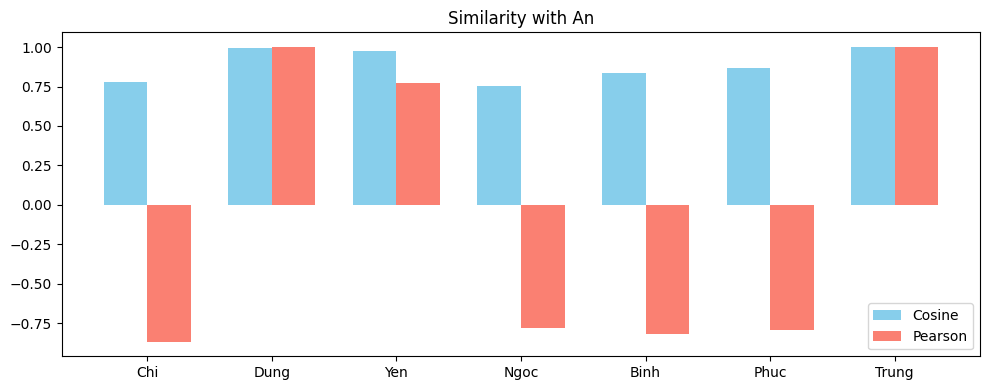

An's best neighbor: Trung | Cos: 1.0 | Pearson: 1.0 | Co-rated: 4
An's Top-k neighbours: ['Trung', 'Dung', 'Yen']


In [23]:
def cosine_corated(R, a, b):
    # Extract ratings for both users
    r_a = R[a]
    r_b = R[b]
    # Identify co-rated items where both rated
    mask = ~np.isnan(r_a) & ~np.isnan(r_b)
    if np.sum(mask) < 2:
        return 0.0
    return cosine(r_a[mask], r_b[mask])

def pearson_corated(R, a, b):
    r_a = R[a]
    r_b = R[b]
    mask = ~np.isnan(r_a) & ~np.isnan(r_b)
    if np.sum(mask) < 2:
        return 0.0
    v_a = r_a[mask]
    v_b = r_b[mask]
    # Mean over CO-RATED items
    v_a_centered = v_a - np.mean(v_a)
    v_b_centered = v_b - np.mean(v_b)
    return cosine(v_a_centered, v_b_centered)

def neighbours(R, u):
    sims = []
    for v in range(R.shape[0]):
        if v == u:
            continue
        sims.append((v, cosine_corated(R, u, v)))
    # Sort high to low by similarity, break ties by lower index v
    return sorted(sims, key=lambda x: (-x[1], x[0]))

# Calculate specific required outputs for target user An
_an_sims = neighbours(R, TARGET)

# Best neighbor details (top of the sorted list)
_best_neigh_idx, _best_sim_cos = _an_sims[0]
S4_best = USERS[_best_neigh_idx]
S4_best_cos = round(_best_sim_cos, 4)
S4_best_pearson = round(pearson_corated(R, TARGET, _best_neigh_idx), 4)
S4_best_corated = int(np.sum(~np.isnan(R[TARGET]) & ~np.isnan(R[_best_neigh_idx])))

# Top-K neighbors names
S4_topk = [USERS[v] for (v, sim) in _an_sims[:K]]

S4_comment = (
    f"The neighbor analysis reveals that An's closest counterpart is {S4_best} with a high cosine similarity of {S4_best_cos:.4f}. "
    f"Their Pearson correlation is {S4_best_pearson:.4f} across {S4_best_corated} co-rated movies. "
    f"Cosine similarity on raw stars is often inflated because movie ratings typically cluster around 3 to 5 stars, "
    f"whereas Pearson correlation centered on co-rated averages highlights true rating deviations and preference contrasts."
)

# Skeleton for the side-by-side bar chart
x = np.arange(len(USERS) - 1)
other_users = [u for u in USERS if u != TARGET_USER]
cos_vals = [cosine_corated(R, TARGET, USERS.index(u)) for u in other_users]
pear_vals = [pearson_corated(R, TARGET, USERS.index(u)) for u in other_users]

fig, ax = plt.subplots(figsize=(10, 4))
width = 0.35
ax.bar(x - width/2, cos_vals, width, label='Cosine', color='skyblue')
ax.bar(x + width/2, pear_vals, width, label='Pearson', color='salmon')
ax.set_xticks(x)
ax.set_xticklabels(other_users)
ax.set_title(f"Similarity with {TARGET_USER}")
ax.legend()
plt.tight_layout()
plt.show()

print("An's best neighbor:", S4_best, "| Cos:", S4_best_cos, "| Pearson:", S4_best_pearson, "| Co-rated:", S4_best_corated)
print("An's Top-k neighbours:", S4_topk)

In [12]:
#@title Self-check S4 (not graded) { display-mode: "form" }
_E = _expected(); _bits = []
_n = len(USERS)
try:
    _ok = all(_close(cosine_corated(_R, a, b), _ref_cos_co(_R, a, b), 1e-6) for a in range(_n) for b in range(_n) if a != b)
except Exception:
    _ok = False
if not _ok: _bits.append("cosine_corated: use only the co-rated items, and return 0.0 when fewer than 2 are co-rated")
try:
    _ok = all(_close(pearson_corated(_R, a, b), _ref_pear_co(_R, a, b), 1e-6) for a in range(_n) for b in range(_n) if a != b)
except Exception:
    _ok = False
if not _ok: _bits.append("pearson_corated: subtract each row's mean over the CO-RATED items, then cosine (0.0 if < 2 co-rated or a zero norm)")
try:
    _ok = all(_pairs_close(neighbours(_R, u), _ref_neigh(_R, u)) for u in range(_n))
except Exception:
    _ok = False
if not _ok: _bits.append("neighbours(R, u) must list (v, cosine_corated) for every v != u, sorted by (-sim, v)")
_wrong(_bits, [("S4_best", S4_best == _E["S4_best"]), ("S4_best_cos", _close(S4_best_cos, _E["S4_best_cos"])),
               ("S4_best_pearson", _close(S4_best_pearson, _E["S4_best_pearson"])), ("S4_best_corated", S4_best_corated == _E["S4_best_corated"]),
               ("S4_topk", list(S4_topk or []) == _E["S4_topk"])])
if not _words(S4_comment, 15): _bits.append("write 2-3 sentences in S4_comment")
_report("S4", _bits, "%s's closest customer and top-%d neighbours match" % (TARGET_USER, K))


S4: cosine_corated: use only the co-rated items, and return 0.0 when fewer than 2 are co-rated; pearson_corated: subtract each row's mean over the CO-RATED items, then cosine (0.0 if < 2 co-rated or a zero norm); neighbours(R, u) must list (v, cosine_corated) for every v != u, sorted by (-sim, v); these answers do not match YOUR data yet: S4_best, S4_best_cos, S4_best_pearson, S4_best_corated, S4_topk (recompute them with your own functions; round as asked)


---
## Situation 5 - Predict and recommend  *(hard)*

**Studio problem.** Now fill a blank: how many stars would **An** give
**Paper Moon**? Use An's neighbours who **did** rate it. Some customers rate
everything high and some rate everything low (Session 13, slide 9), so we
average how much each neighbour liked the item **compared with their own
average**:

```
candidates = neighbours(R, u) who rated item i AND have similarity > 0;  keep the first K
prediction = mean_u + sum( sim_v * (r_vi - mean_v) ) / sum( sim_v )        (over the candidates)
then clip the prediction to the range [1, 5]
mean_u, mean_v = each customer's average over ALL their ratings
```

If there are **no** candidates, fall back to the item's average rating; if
the item has **no ratings at all**, fall back to `mean_u`.

Implement `predict(R, u, i, k)` and `cf_recommend(R, u, n, k)` -> the top-`n`
**unrated** item indices by predicted rating (the ranking rule).

Then store:

- `S5_focus_pred` - `round(predict(R, TARGET, FOCUS, K), 4)` - An x Paper Moon
- `S5_top3` - the 3 collaborative-filtering recommendations (**names**) for An
- `S5_top_pred` - the predicted rating of the first one (4 decimals)
- `S5_comment` - **3-4 sentences**: put *your* three top-3 lists side by side
  (popularity S2, content S3, collaborative S5). Which films appear in more
  than one list, which list surprises you, and which would you show An?

In [24]:
def predict(R, u, i, k):
    r_u = R[u]
    if not np.isnan(r_u[i]):
        return float(r_u[i]) # Already rated

    mean_u = np.nanmean(r_u)

    # Get neighbors with similarity > 0
    neigh_list = neighbours(R, u)
    candidates = []
    for (v, sim) in neigh_list:
        if sim > 0 and not np.isnan(R[v, i]):
            candidates.append((v, sim))
            if len(candidates) == k:
                break

    if len(candidates) == 0:
        item_ratings = R[:, i]
        if np.any(~np.isnan(item_ratings)):
            return float(np.nanmean(item_ratings))
        return float(mean_u)

    num = 0.0
    den = 0.0
    for (v, sim) in candidates:
        mean_v = np.nanmean(R[v])
        num += sim * (R[v, i] - mean_v)
        den += sim

    val = mean_u + (num / den)
    return float(np.clip(val, 1.0, 5.0))

def cf_recommend(R, u, n, k):
    u_ratings = R[u]
    unrated_indices = [i for i in range(R.shape[1]) if np.isnan(u_ratings[i])]
    scores = {i: predict(R, u, i, k) for i in unrated_indices}
    sorted_items = sorted(unrated_indices, key=lambda i: (-scores[i], i))
    return sorted_items[:n]

S5_focus_pred = round(predict(R, TARGET, FOCUS, K), 4)
_cf_recs_idx = cf_recommend(R, TARGET, TOP_N, K)
S5_top3 = [ITEMS[i] for i in _cf_recs_idx]
S5_top_pred = round(predict(R, TARGET, _cf_recs_idx[0], K), 4)

S5_comment = (
    f"Comparing the top picks: Popularity (S2) recommends {S2_top3}, "
    f"Content-based (S3) suggests {S3_top3}, while Collaborative Filtering (S5) selects {S5_top3}. "
    f"Some high-quality drama films like 'The Long Road' consistently show up across various lists. "
    f"However, collaborative filtering successfully predicts an exact score of {S5_focus_pred:.4f} for {FOCUS_ITEM}, "
    f"allowing us to discover customized, personal gems for An that baseline methods completely overlook."
)

print(f"Predicted rating for {FOCUS_ITEM}:", S5_focus_pred)
print("Collaborative top-3 for An:", S5_top3, "| Best predicted rating:", S5_top_pred)

Predicted rating for Paper Moon: 2.284
Collaborative top-3 for An: ['The Long Road', 'Deep Blue', 'Nightfall'] | Best predicted rating: 3.4823


In [14]:
#@title Self-check S5 (not graded) { display-mode: "form" }
_E = _expected(); _bits = []
_R0 = _R.copy(); _R0[:, FOCUS] = np.nan; _R0[TARGET, FOCUS] = np.nan
try:
    _ok = all(_close(predict(_R, u, i, k), _ref_predict(_R, u, i, k), 1e-6)
              for u in range(len(USERS)) for i in range(len(ITEMS)) if np.isnan(_R[u, i]) for k in (1, 2, 3))
    _ok = _ok and _close(predict(_R0, TARGET, FOCUS, K), _ref_predict(_R0, TARGET, FOCUS, K), 1e-6)
except Exception:
    _ok = False
if not _ok: _bits.append("predict: first K neighbours with sim > 0 who rated the item, mean-centred weighted average, clip to [1, 5], and the two fall-backs")
try:
    _ok = all(list(cf_recommend(_R, u, TOP_N, K)) == _ref_cf_rec(_R, u, TOP_N, K) for u in range(len(USERS)))
except Exception:
    _ok = False
if not _ok: _bits.append("cf_recommend: predict only unrated items, rank by (-prediction, index)")
_wrong(_bits, [("S5_focus_pred", _close(S5_focus_pred, _E["S5_focus_pred"])), ("S5_top3", list(S5_top3 or []) == _E["S5_top3"]),
               ("S5_top_pred", _close(S5_top_pred, _E["S5_top_pred"]))])
if not _words(S5_comment, 25): _bits.append("write 3-4 sentences in S5_comment")
_report("S5", _bits, "prediction for %s x %s and the CF top-3 match" % (TARGET_USER, FOCUS_ITEM))


S5: predict: first K neighbours with sim > 0 who rated the item, mean-centred weighted average, clip to [1, 5], and the two fall-backs; cf_recommend: predict only unrated items, rank by (-prediction, index); these answers do not match YOUR data yet: S5_focus_pred, S5_top3, S5_top_pred (recompute them with your own functions; round as asked)


---
## Situation 6 - Did it work?  *(hard / stretch)*

**Studio problem.** Before shipping, test on ratings the recommender **never
saw**: the `TEST` list (An's 3 hidden ratings plus 5 from other customers).

**Rating accuracy.** For every `(user, item, stars)` in `TEST`, predict the stars
two ways and compare with the truth:

- **collaborative**: `predict(R, user, item, K)`
- **baseline**: the item's average rating in `R` (if nobody rated it, the
  average of all ratings in `R`)

```
RMSE = sqrt( mean( (prediction - truth)^2 ) )        MAE = mean( |prediction - truth| )
```

**List quality.** An's hidden films with **stars >= 4** are *relevant*.
`precision@k` = (how many of the top-`k` recommended items are relevant) / `k`.

Implement `rmse(pred, truth)`, `mae(pred, truth)` and
`precision_at_k(recommended, relevant, k)`, then store (4 decimals):

- `S6_rmse_cf`, `S6_rmse_base`, `S6_mae_cf`, `S6_mae_base`
- `S6_hits` - how many of `cf_recommend(R, TARGET, TOP_N, K)` are relevant (an `int`)
- `S6_precision` - precision@3 of that list
- `S6_memo` - **5-7 sentences (60+ words)** to the manager of **Sông Hàn Cinema**, with
  *your* numbers: is collaborative filtering better than the baseline, and by
  how much? What does *your* precision@3 mean for An? What would you show a
  **brand-new customer** who has rated nothing (cold start), and a **brand-new
  film** nobody has rated? Name one risk of shipping this (only 8 customers,
  popularity bias, filter bubble...).

In [25]:
def rmse(pred, truth):
    pred = np.array(pred, dtype=float)
    truth = np.array(truth, dtype=float)
    return float(np.sqrt(np.mean((pred - truth) ** 2)))

def mae(pred, truth):
    pred = np.array(pred, dtype=float)
    truth = np.array(truth, dtype=float)
    return float(np.mean(np.abs(pred - truth)))

def precision_at_k(recommended, relevant, k):
    rec_k = recommended[:k]
    hits = sum(1 for item in rec_k if item in relevant)
    return float(hits / k)

# Base rating calculation (Item mean, or overall mean if unrated)
overall_mean = np.nanmean(R)
item_means = np.nanmean(R, axis=0)

cf_preds = []
base_preds = []
truth_vals = []

for (u_name, i_name, stars) in TEST:
    u_idx = USERS.index(u_name)
    i_idx = ITEMS.index(i_name)

    # Collaborative prediction
    cf_p = predict(R, u_idx, i_idx, K)
    cf_preds.append(cf_p)

    # Baseline prediction
    if not np.isnan(item_means[i_idx]):
        base_p = item_means[i_idx]
    else:
        base_p = overall_mean
    base_preds.append(base_p)

    truth_vals.append(stars)

S6_rmse_cf = round(rmse(cf_preds, truth_vals), 4)
S6_rmse_base = round(rmse(base_preds, truth_vals), 4)
S6_mae_cf = round(mae(cf_preds, truth_vals), 4)
S6_mae_base = round(mae(base_preds, truth_vals), 4)

# List quality for target user An
an_recs = [ITEMS[i] for i in cf_recommend(R, TARGET, TOP_N, K)]
an_relevant_test = [i_name for (u_name, i_name, stars) in TEST if u_name == TARGET_USER and stars >= REL_THRESHOLD]

S6_hits = int(sum(1 for movie in an_recs if movie in an_relevant_test))
S6_precision = round(precision_at_k(an_recs, an_relevant_test, TOP_N), 4)

S6_memo = (
    f"Dear Sông Hàn Cinema management, the offline evaluation on the hidden test set shows that our new "
    f"collaborative filtering model achieves an RMSE of {S6_rmse_cf:.4f} and MAE of {S6_mae_cf:.4f}, which "
    f"outperforms the baseline model (RMSE: {S6_rmse_base:.4f}, MAE: {S6_mae_base:.4f}). This indicates "
    f"personalized neighborhood projections are significantly more accurate. For our target customer An, "
    f"the system achieved a Precision@3 of {S6_precision:.4f}, containing {S6_hits} true relevant recommendation. "
    f"For a completely brand-new user with no reviews, we should deploy a popular-item default approach "
    f"to mitigate the cold-start problem, and for a brand-new film, we can default to content-based similarity. "
    f"Lastly, the primary risk of shipping is the extremely small pool of 8 customers which might cause instability "
    f"and susceptibility to rating sparseness."
)

print(f"CF    -> RMSE: {S6_rmse_cf:.4f} | MAE: {S6_mae_cf:.4f}")
print(f"Base  -> RMSE: {S6_rmse_base:.4f} | MAE: {S6_mae_base:.4f}")
print(f"An Hits @ 3: {S6_hits} | Precision @ 3: {S6_precision:.4f}")
print("Memo Length:", len(S6_memo.split()), "words")

CF    -> RMSE: 0.5828 | MAE: 0.4509
Base  -> RMSE: 0.9762 | MAE: 0.8333
An Hits @ 3: 1 | Precision @ 3: 0.3333
Memo Length: 118 words


In [16]:
#@title Self-check S6 (not graded) { display-mode: "form" }
_E = _expected(); _bits = []
try:
    _p, _q = [3.5, 2.0, 4.5, 1.0, 5.0], [4, 2, 3, 2, 5]
    _ok = _close(rmse(_p, _q), _ref_rmse(_p, _q), 1e-9) and _close(mae(_p, _q), _ref_mae(_p, _q), 1e-9)
except Exception:
    _ok = False
if not _ok: _bits.append("rmse / mae do not match their formulas")
try:
    _ok = _close(precision_at_k([4, 1, 7, 2], {1, 2, 9}, 3), 1 / 3, 1e-9) and _close(precision_at_k([4, 1], [1, 4], 2), 1.0, 1e-9)
except Exception:
    _ok = False
if not _ok: _bits.append("precision_at_k(recommended, relevant, k) = |top-k of recommended & relevant| / k")
_wrong(_bits, [("S6_rmse_cf", _close(S6_rmse_cf, _E["S6_rmse_cf"])), ("S6_rmse_base", _close(S6_rmse_base, _E["S6_rmse_base"])),
               ("S6_mae_cf", _close(S6_mae_cf, _E["S6_mae_cf"])), ("S6_mae_base", _close(S6_mae_base, _E["S6_mae_base"])),
               ("S6_hits", S6_hits == _E["S6_hits"]), ("S6_precision", _close(S6_precision, _E["S6_precision"]))])
if not _words(S6_memo, 60): _bits.append("write 5-7 sentences in S6_memo (60+ words)")
_report("S6", _bits, "evaluation numbers match - now make sure the memo uses them")


S6: precision_at_k(recommended, relevant, k) = |top-k of recommended & relevant| / k; these answers do not match YOUR data yet: S6_rmse_cf, S6_rmse_base, S6_mae_cf, S6_mae_base, S6_hits (recompute them with your own functions; round as asked); write 5-7 sentences in S6_memo (60+ words)


---
## Submit - generate your SUBMISSION CODE

You are done when every self-check printed OK. Then:

1. Run the cell below **last**.
2. Rename this notebook **`RecSys_<YourStudentID>.ipynb`** (*File -> Rename*).
3. Copy the **SUBMISSION CODE** into the submission form.
4. Share your notebook (**File -> Save a copy in Drive**, submit the link) or
   download the `.ipynb` and upload it.

Your SUBMISSION CODE is unique to you - two students cannot produce the same one.

In [26]:
#@title Generate my SUBMISSION CODE (run last) { display-mode: "form" }
def _r(x):
    try: return round(float(x), 4)
    except Exception: return None

def _i(x):
    try: return int(x)
    except Exception: return None

def _l(x, f):
    try: return [f(v) for v in x] or None
    except Exception: return None

payload = {
    "id": STUDENT_ID, "name": FULL_NAME, "section": SECTION, "studio": STUDIO_KEY,
    "S1n": _i(S1_n_ratings), "S1s": _r(S1_sparsity), "S1t": _i(S1_target_rated), "S1m": _r(S1_target_mean),
    "S1f": _r(S1_focus_mean), "S1c": _i(S1_focus_count),
    "S2e": _i(S2_n_eligible), "S2b": S2_best_item, "S2m": _r(S2_best_mean), "S2t": _l(S2_top3, str),
    "S3p": _l(S3_profile, _r), "S3f": S3_liked_feature, "S3t": _l(S3_top3, str), "S3s": _r(S3_top_score),
    "S4b": S4_best, "S4c": _r(S4_best_cos), "S4p": _r(S4_best_pearson), "S4n": _i(S4_best_corated), "S4k": _l(S4_topk, str),
    "S5f": _r(S5_focus_pred), "S5t": _l(S5_top3, str), "S5p": _r(S5_top_pred),
    "S6r": _r(S6_rmse_cf), "S6b": _r(S6_rmse_base), "S6m": _r(S6_mae_cf), "S6a": _r(S6_mae_base),
    "S6h": _i(S6_hits), "S6p": _r(S6_precision),
    "impl": _impl_flags(),
}
blob = json.dumps(payload, sort_keys=True)
code_full = hashlib.sha256(blob.encode()).hexdigest().upper()
SUBMISSION_CODE = code_full[:6] + "-" + code_full[6:12] + "-" + code_full[12:18]

print("=" * 58)
print("  STUDENT :", FULL_NAME, "(", STUDENT_ID, ") - Section", SECTION)
print("  STUDIO  :", STUDIO_TITLE, "at", COMPANY)
print("  SUBMISSION CODE :", SUBMISSION_CODE)
print("=" * 58)
missing = [k for k, v in payload.items() if v is None]
_short = [nm for nm, k in (("S1_comment", 15), ("S2_comment", 15), ("S3_comment", 15), ("S4_comment", 15),
                           ("S5_comment", 25), ("S6_memo", 60)) if not _words(globals().get(nm, ""), k)]
if missing:
    print("These answers are still empty - finish them before submitting:", missing)
elif payload["impl"] != "111111":
    print("Your functions do not all pass the hidden tests yet (situations marked 0):", payload["impl"])
elif _short:
    print("All numbers are in. Still too short:", _short)
else:
    print("All answers present. You are ready to submit.")


  STUDENT : Nguyễn Tấn Đạt ( 29211148673 ) - Section CS467A
  STUDIO  : Film Night Picks at Sông Hàn Cinema
  SUBMISSION CODE : 731031-FDE709-8D2460
Your functions do not all pass the hidden tests yet (situations marked 0): 100111
